In [9]:
using Pkg
Pkg.activate("/Users/alia/Desktop/envs/ants")
using BifurcationKit
using Plots
using DifferentialEquations
using LaTeXStrings
using JLD2
using CSV
using DataFrames
using Plots.PlotMeasures

xgfs_normal12 = [(235, 172, 35), (184, 0, 88), (0, 140, 249), (0, 110, 0), (0, 187, 173), (209, 99, 230), (178, 69, 2), (255, 146, 135), (89, 84, 214), (0, 198, 248), (135, 133, 0), (0, 167, 108), (189, 189, 189)]
pal = [RGB(r/255, g/255, b/255) for (r,g,b) in xgfs_normal12]

  Activating project at `~/Desktop/envs/ants`


In [76]:
function induced!(dx,x,p,t)
    (omegaC,n,tau,eps,a0,k0) = p
    C,alphaC,k = x
    dx[1] = alphaC * (1-C) - omegaC * C / (1 + (C/k)^n)
    dx[2] = 1/tau*( eps * (1-C)-a0)
    dx[3] = 1/tau*(( eps * alphaC)-k0)
    return nothing
end

induced! (generic function with 1 method)

In [77]:
u0 = [0.5,0.1,0.1]
tspan = (0,50000.0)
par = (omegaC = 2.0, n = 4, tau = 50, eps = 0.1,a0 = 0.00,k0=0.0)


prob = ODEProblem(induced!,u0,tspan,par)
sol = DifferentialEquations.solve(prob)

C,alphaC,k = sol[1,:],sol[2,:],sol[3,:]

S = 1 .- C;

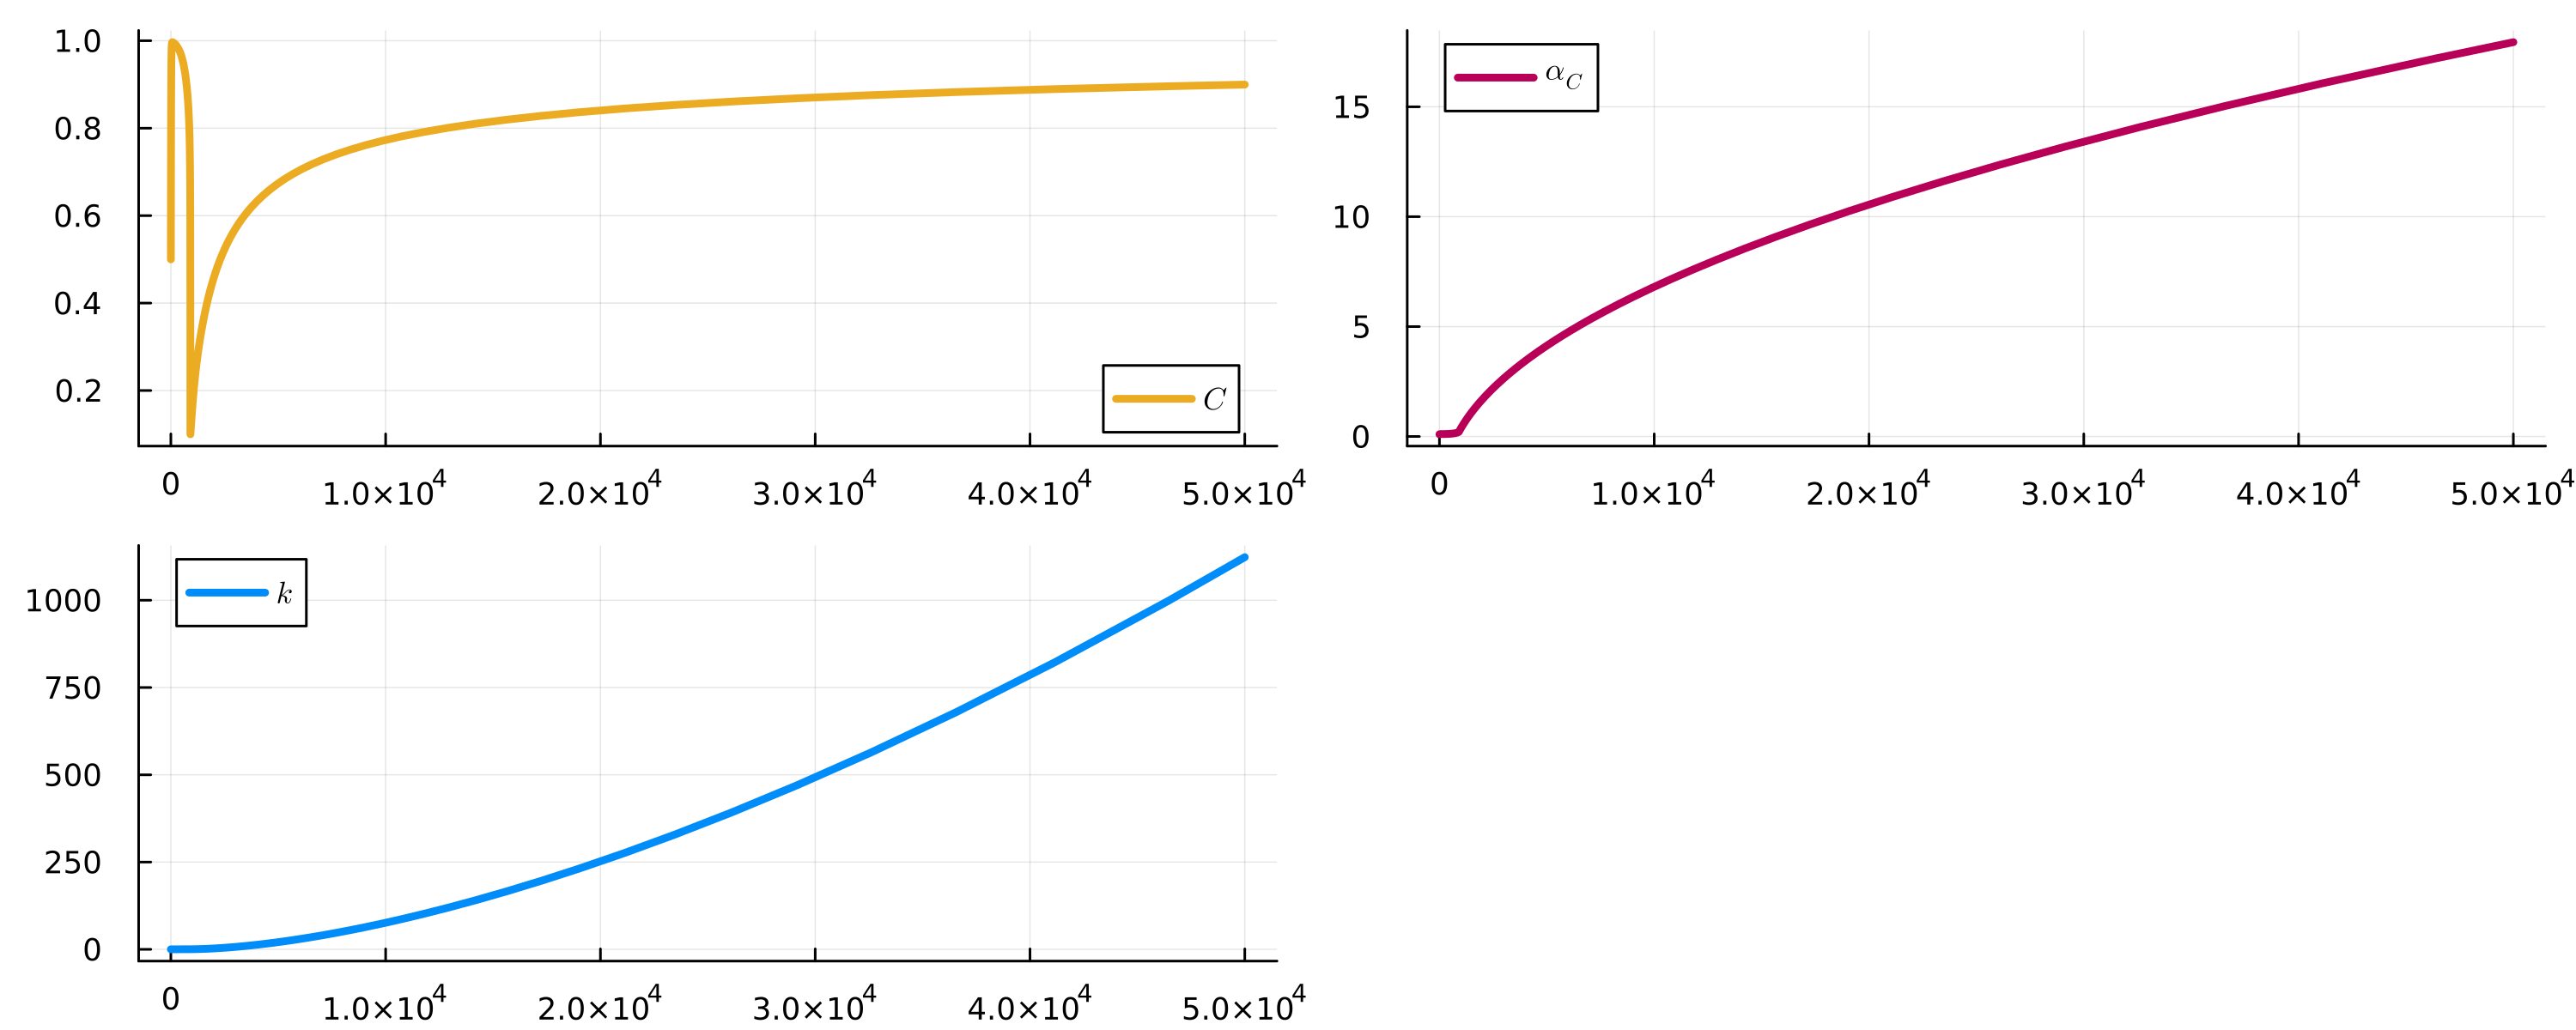

In [83]:
p1 = plot(sol.t,C,   lw=3, color = pal[1],label = L"C")
#plot!(sol.t,S)

p2 = plot(sol.t, alphaC,   lw=3, color = pal[2],label = L"\alpha_C")
p3 = plot(sol.t,k,   lw=3, color = pal[3],label = L"k")

plot(p1,p2,p3,size = (1000,400),dpi = 300)